In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.simplefilter(action='ignore',category=FutureWarning)

In [2]:
# Set random seed for reproducibility
np.random.seed(42)
# Load the dataset
data = pd.read_csv('EastWestAirlines.csv')

In [3]:
# Handle missing values using SimpleImputer (mean or median)
imputer = SimpleImputer(strategy='mean')
data_imputed = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)

In [4]:
# Remove outliers (Optional: Using Z-score or IQR)
# Example using Z-score
from scipy.stats import zscore
data_imputed = data_imputed[(np.abs(zscore(data_imputed)) < 3).all(axis=1)]

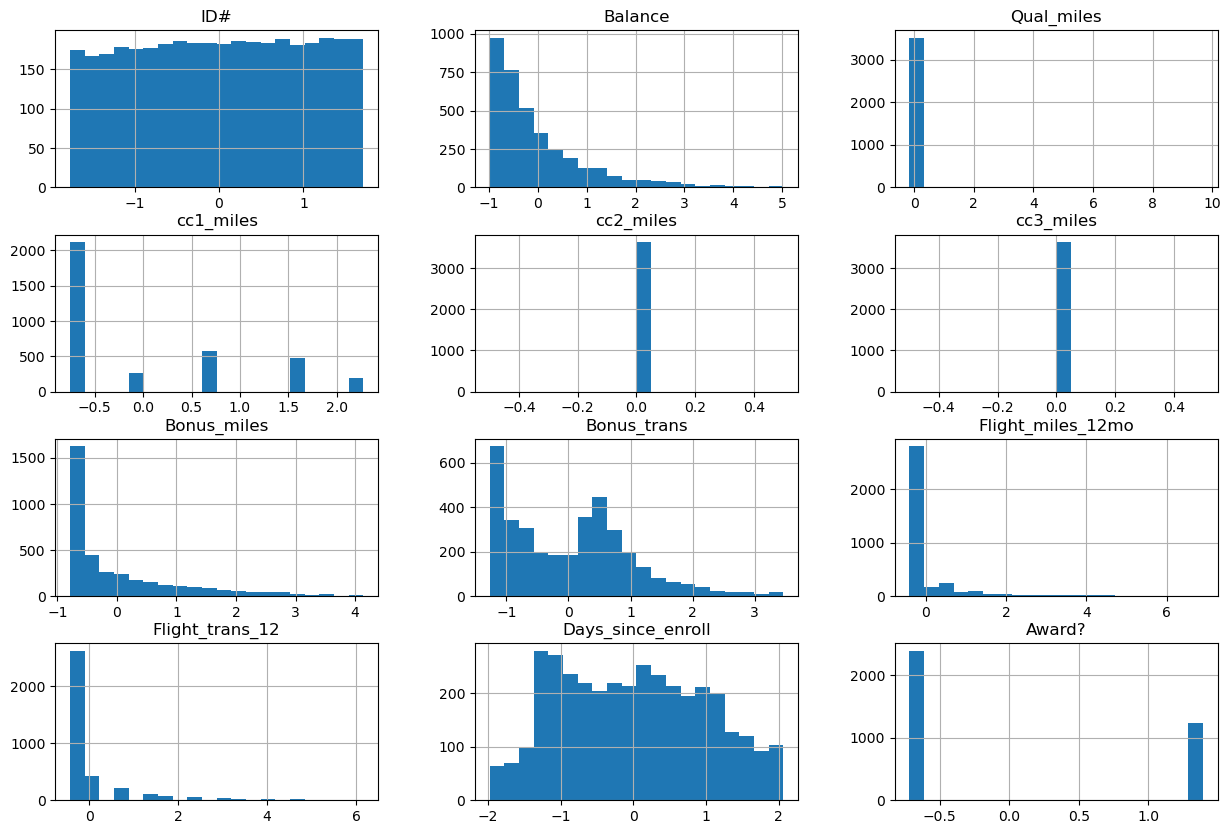

In [5]:
# Feature Scaling
scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data_imputed), columns=data_imputed.columns)
# Visualize the distribution of each feature
data_scaled.hist(bins=20, figsize=(15,10))
plt.show()

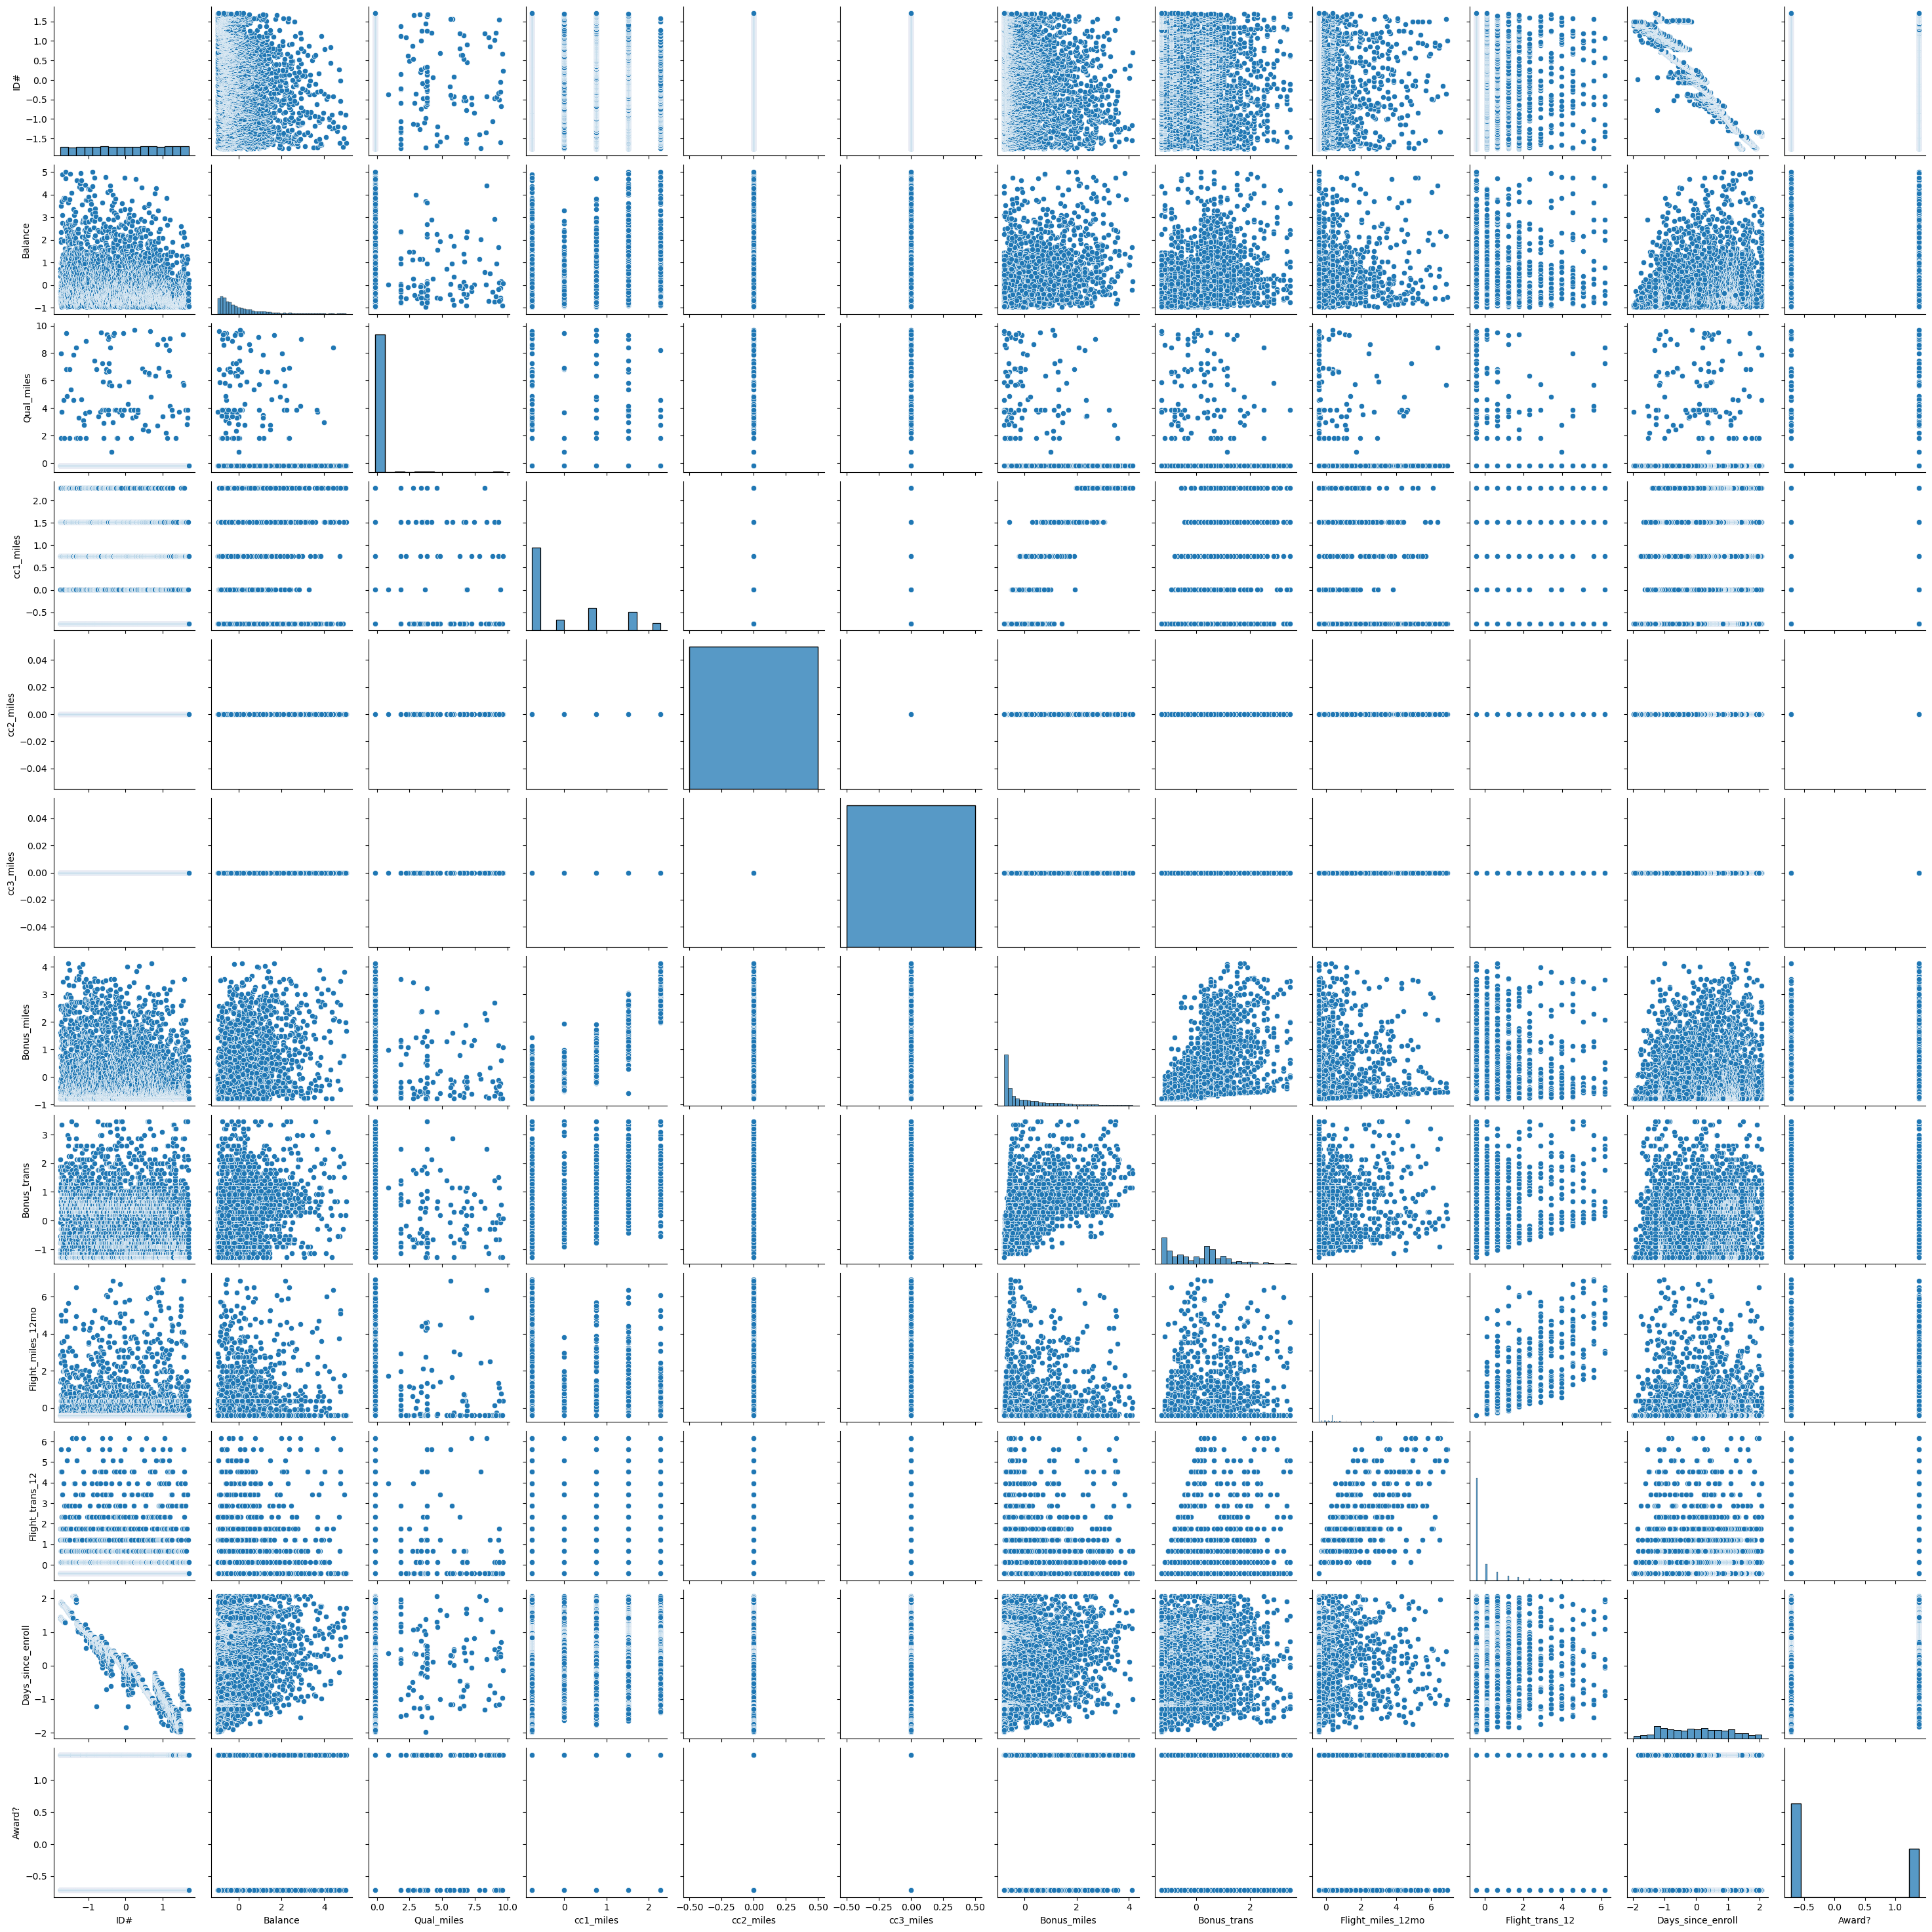

In [6]:
# Pairplot to observe feature relationships
sns.pairplot(data_scaled)
plt.show()
# Elbow method to find optimal K
sse = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data_scaled)
    sse.append(kmeans.inertia_)

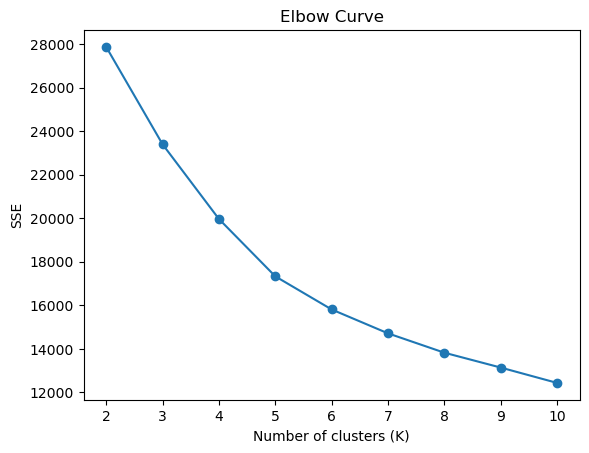

In [7]:
plt.plot(range(2, 11), sse, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('SSE')
plt.title('Elbow Curve')
plt.show()

In [8]:
# Apply K-Means with optimal K (e.g., 3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_labels = kmeans.fit_predict(data_scaled)
# Linkage for dendrogram
linked = linkage(data_scaled, method='ward')

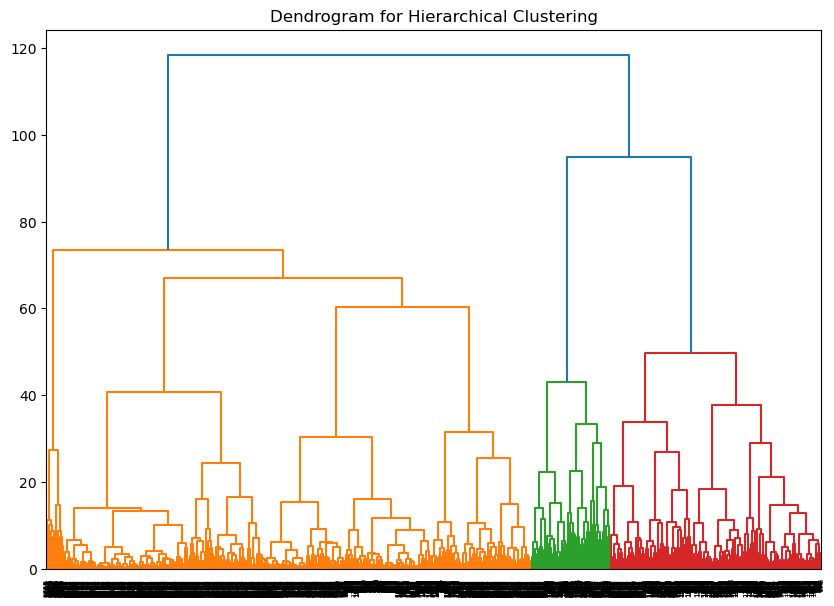

In [9]:
# Dendrogram
plt.figure(figsize=(10, 7))
dendrogram(linked)
plt.title('Dendrogram for Hierarchical Clustering')
plt.show()

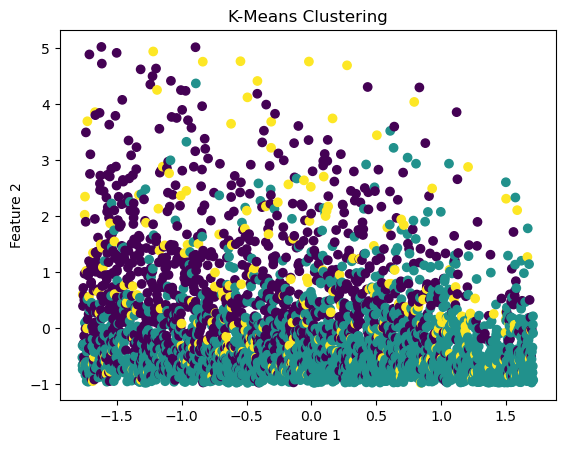

In [10]:
# Apply Hierarchical Clustering
hier_clustering = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
hier_labels = hier_clustering.fit_predict(data_scaled)
# DBSCAN with hyperparameter tuning (eps, min_samples)
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(data_scaled)
# Plot the clusters from K-Means
plt.scatter(data_scaled.iloc[:, 0], data_scaled.iloc[:, 1], c=kmeans_labels, cmap='viridis')
plt.title('K-Means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

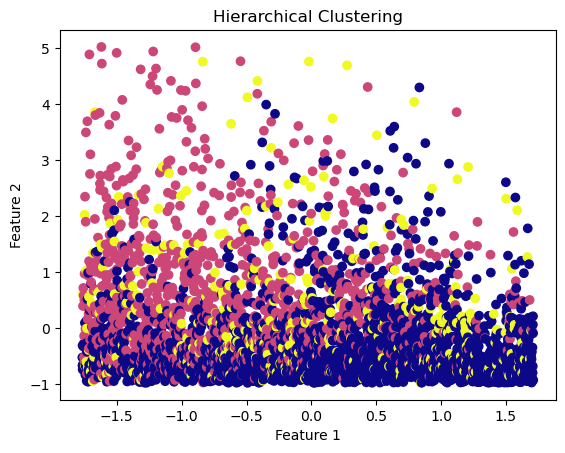

In [11]:
# Plot the clusters from Hierarchical Clustering
plt.scatter(data_scaled.iloc[:, 0], data_scaled.iloc[:, 1], c=hier_labels, cmap='plasma')
plt.title('Hierarchical Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

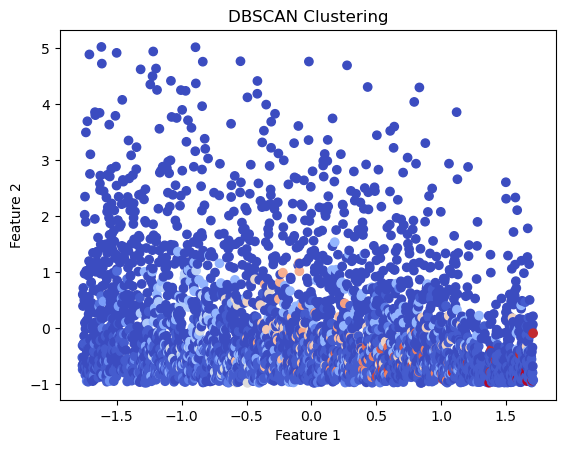

Silhouette Score for K-Means: 0.29


In [12]:
# Plot the clusters from DBSCAN
plt.scatter(data_scaled.iloc[:, 0], data_scaled.iloc[:, 1], c=dbscan_labels, cmap='coolwarm')
plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()
# Silhouette Score for K-Means
kmeans_silhouette = silhouette_score(data_scaled, kmeans_labels)
print(f'Silhouette Score for K-Means: {kmeans_silhouette:.2f}')

In [13]:
# Silhouette Score for DBSCAN
dbscan_silhouette = silhouette_score(data_scaled, dbscan_labels) if len(set(dbscan_labels)) > 1 else -1
print(f'Silhouette Score for DBSCAN: {dbscan_silhouette:.2f}')

Silhouette Score for DBSCAN: -0.40


In [14]:
# Silhouette Score for Hierarchical Clustering
hier_silhouette = silhouette_score(data_scaled, hier_labels)
print(f'Silhouette Score for Hierarchical Clustering: {hier_silhouette:.2f}')

Silhouette Score for Hierarchical Clustering: 0.26
